In [80]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [81]:
from movebench.study import Study

In [82]:
study = Study.load('5a280544-06db-4c85-9713-842547972edd')

In [83]:
# result = study.download_rasters(splits=["train", "test"],
#                                 layers=["dist_water"],
#                                 skip_existing=False)

In [ ]:
train_ds = study.chip_dataset(split='train', 
                            #   auto_normalize=False, # False to look at raw data
                              # force_normalize=True
                              )
print(f"Train dataset: {len(train_ds)} samples")

[movebench] Computing normalization for 19 layers: ['modis_lst', 'modis_vi', 'modis_ndsi', 'modis_bai', 'era5_land', 'era5', 'dem', 'slope', 'aspect', 'rugosity', 'dist_water', 'orographic_uplift', 'thermal_uplift', 'modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg', 'hii', 'bioclim', 'dynamic_world']


Computing stats:   0%|          | 0/1000 [00:02<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
sample_idx = 1234

x, mask, transform, crs = train_ds[sample_idx]
print(f"Sample shape: {x.shape}")

Sample shape: torch.Size([79, 79, 77])


In [ ]:
import matplotlib.pyplot as plt                                                                                                                                 
import numpy as np                                                                                                                                              
from movebench.config import LAYER_ORDER, LAYERS, get_channel_indices                                                                                           
                                                                                                                                                                
# Channel layout (63 total)                                                                                                                                     
channel_indices = get_channel_indices()                                                                                                                         
for layer_name, (start, end) in channel_indices.items():                                                                                                        
    print(f"{layer_name:20s}: channels {start:2d}-{end-1:2d} ({end-start} bands)")                                                                              
                                                                                                                                                                


modis_lst           : channels  0- 1 (2 bands)
modis_vi            : channels  2- 3 (2 bands)
modis_ndsi          : channels  4- 4 (1 bands)
modis_bai           : channels  5- 5 (1 bands)
era5_land           : channels  6-17 (12 bands)
era5                : channels 18-20 (3 bands)
dem                 : channels 21-21 (1 bands)
slope               : channels 22-22 (1 bands)
aspect              : channels 23-24 (2 bands)
rugosity            : channels 25-25 (1 bands)
dist_water          : channels 26-26 (1 bands)
orographic_uplift   : channels 27-27 (1 bands)
thermal_uplift      : channels 28-28 (1 bands)
modis_lc            : channels 29-46 (18 bands)
modis_cvf_tree      : channels 47-47 (1 bands)
modis_cvf_nontree   : channels 48-48 (1 bands)
modis_cvf_nonveg    : channels 49-49 (1 bands)
hii                 : channels 50-50 (1 bands)
bioclim             : channels 51-69 (19 bands)
dynamic_world       : channels 70-78 (9 bands)


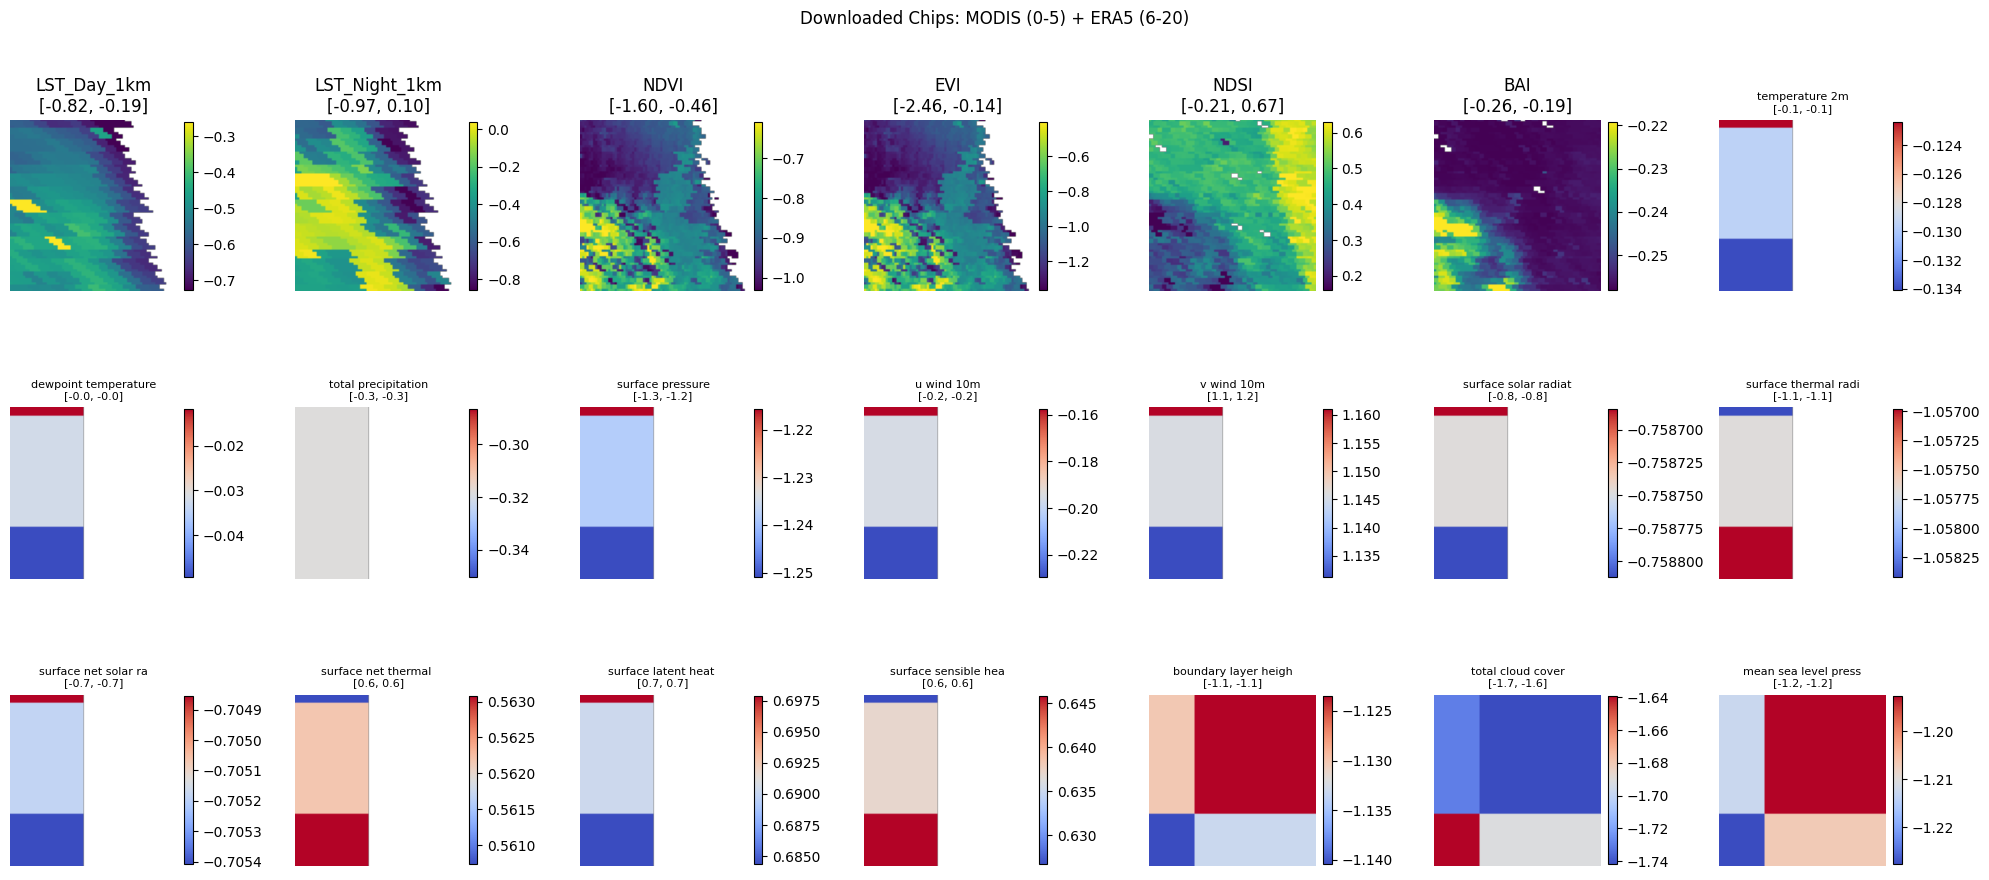

In [ ]:
# Plot MODIS and ERA5 bands using names from config
fig, axes = plt.subplots(3, 7, figsize=(20, 9))
axes = axes.flatten()

# MODIS bands: LST (2), VI (2), NDSI (1), BAI (1) = 6 bands total
modis_layers = ['modis_lst', 'modis_vi', 'modis_ndsi', 'modis_bai']
modis_names = []
for layer in modis_layers:
    modis_names.extend(LAYERS[layer].bands)

modis_start = channel_indices['modis_lst'][0]
for i, name in enumerate(modis_names):
    ax = axes[i]
    ch = modis_start + i
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='viridis')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{name}\n[{valid.min():.2f}, {valid.max():.2f}]')
    else:
        ax.imshow(display_data)
        ax.set_title(f'{name}\n(no valid data)')
    ax.axis('off')

# ERA5 bands: era5_land (12) + era5 (3) = 15 bands
era5_names = LAYERS['era5_land'].bands + LAYERS['era5'].bands

era5_start = channel_indices['era5_land'][0]
for i, name in enumerate(era5_names):
    ax = axes[6 + i]
    ch = era5_start + i
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='coolwarm')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        # Shorten long names for display
        short_name = name.replace('_', ' ').replace('component of ', '')[:20]
        ax.set_title(f'{short_name}\n[{valid.min():.1f}, {valid.max():.1f}]', fontsize=8)
    else:
        ax.imshow(display_data)
        ax.set_title(f'{name}\n(no valid)')
    ax.axis('off')

plt.tight_layout()
plt.suptitle('Downloaded Chips: MODIS (0-5) + ERA5 (6-20)', y=1.02)
plt.show()

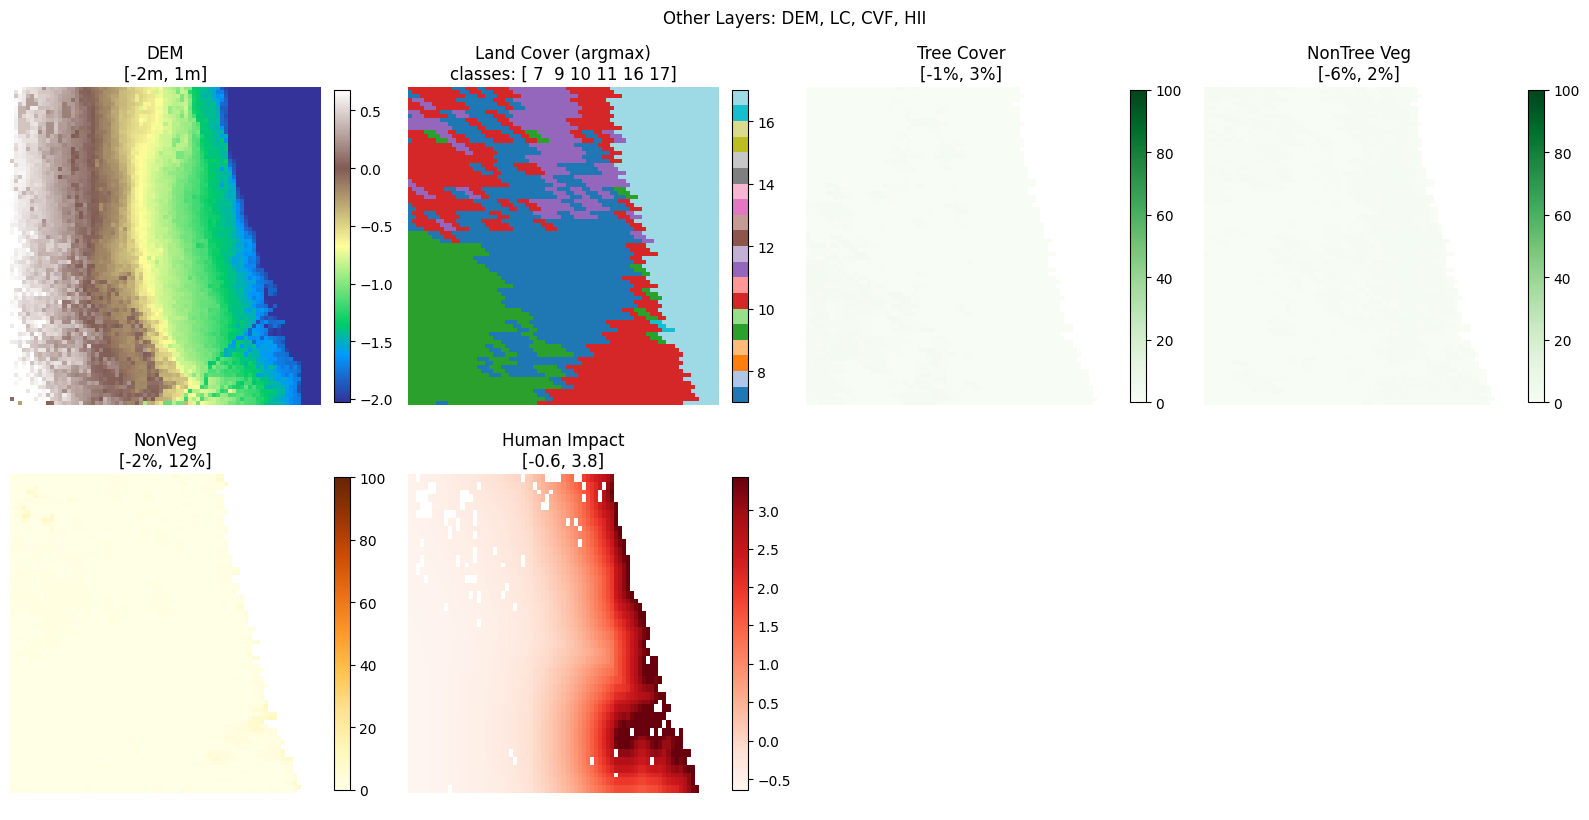

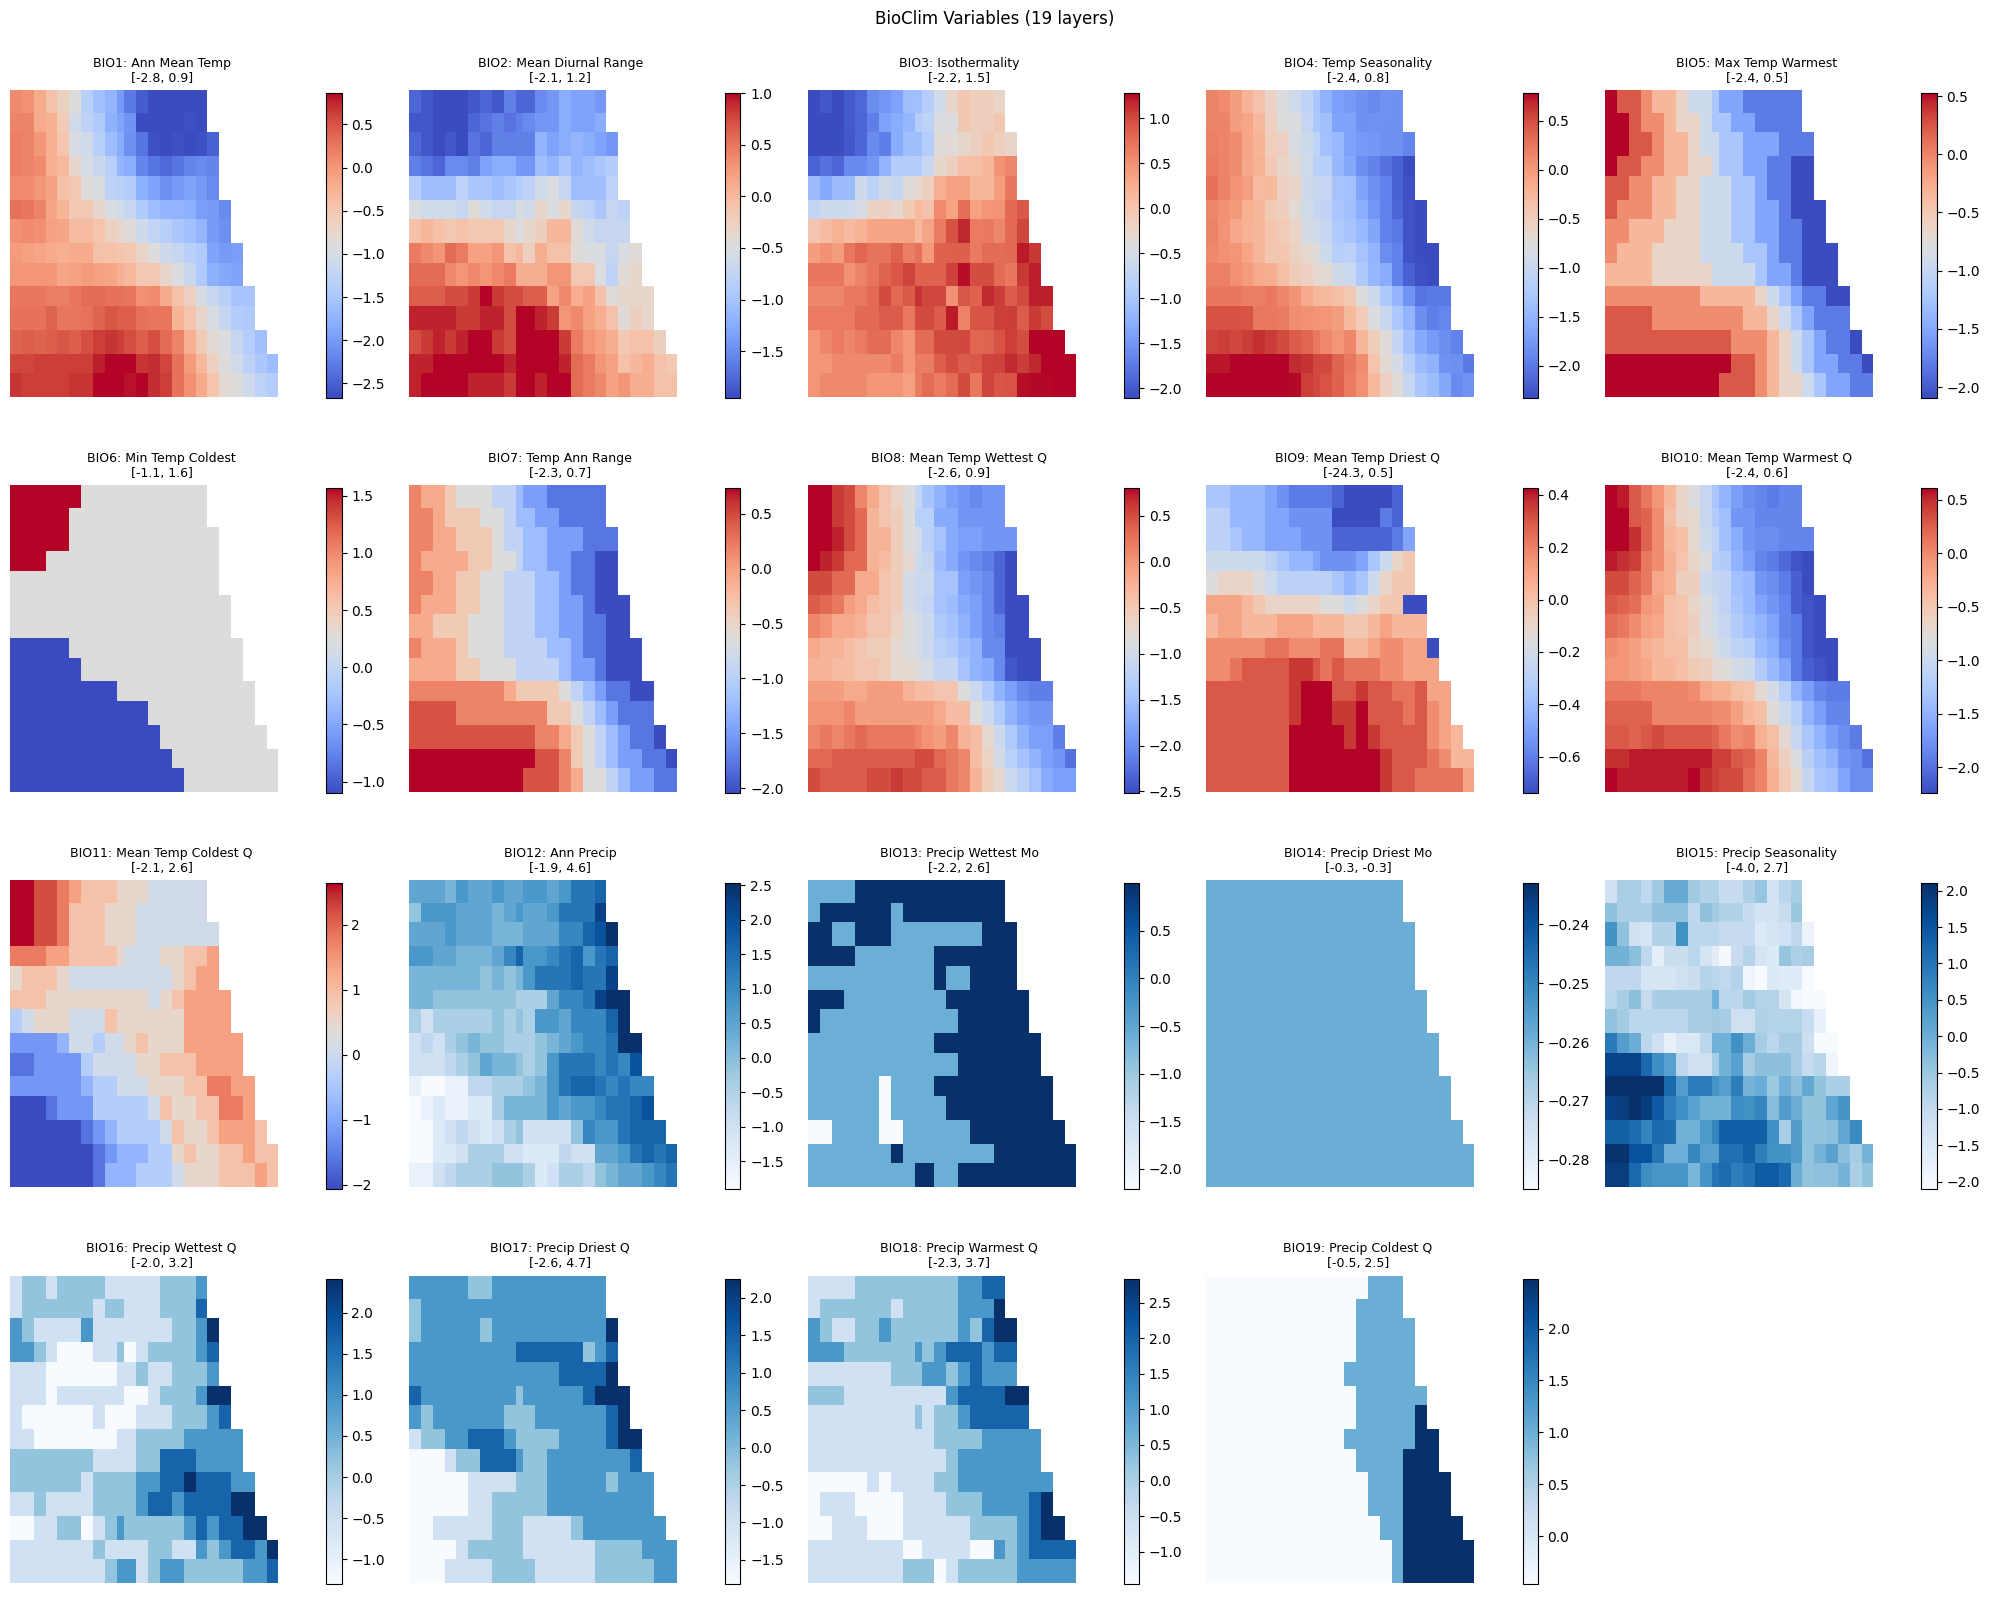

In [ ]:
# Plot DEM, Land Cover, CVF, HII using channel_indices
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

# DEM
ax = axes[0]
dem_start = channel_indices['dem'][0]
dem = x[dem_start].numpy()
valid_mask_dem = mask[dem_start].numpy()
valid = dem[valid_mask_dem]
display_dem = np.where(valid_mask_dem, dem, np.nan)
if len(valid) > 0:
    im = ax.imshow(display_dem, vmin=np.percentile(valid, 2), vmax=np.percentile(valid, 98), cmap='terrain')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'DEM\n[{valid.min():.0f}m, {valid.max():.0f}m]')
ax.axis('off')

# Land Cover (one-hot) - show argmax
ax = axes[1]
lc_start, lc_end = channel_indices['modis_lc']
lc_onehot = x[lc_start:lc_end].numpy()
lc_class = np.argmax(lc_onehot, axis=0)
im = ax.imshow(lc_class, cmap='tab20')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title(f'Land Cover (argmax)\nclasses: {np.unique(lc_class)}')
ax.axis('off')

# CVF bands
cvf_layers = ['modis_cvf_tree', 'modis_cvf_nontree', 'modis_cvf_nonveg']
cvf_display_names = ['Tree Cover', 'NonTree Veg', 'NonVeg']
for i, (layer, name) in enumerate(zip(cvf_layers, cvf_display_names)):
    ax = axes[2 + i]
    ch = channel_indices[layer][0]
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    if len(valid) > 0:
        im = ax.imshow(display_data, vmin=0, vmax=100, cmap='Greens' if i < 2 else 'YlOrBr')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{name}\n[{valid.min():.0f}%, {valid.max():.0f}%]')
    ax.axis('off')

# HII
ax = axes[5]
hii_start = channel_indices['hii'][0]
hii = x[hii_start].numpy()
valid_mask_hii = mask[hii_start].numpy()
valid = hii[valid_mask_hii]
display_hii = np.where(valid_mask_hii, hii, np.nan)
if len(valid) > 0:
    im = ax.imshow(display_hii, vmin=np.percentile(valid, 2), vmax=np.percentile(valid, 98), cmap='Reds')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Human Impact\n[{valid.min():.1f}, {valid.max():.1f}]')
ax.axis('off')

# Hide unused axes
axes[6].axis('off')
axes[7].axis('off')

plt.tight_layout()
plt.suptitle('Other Layers: DEM, LC, CVF, HII', y=1.02)
plt.show()

# BioClim - all 19 variables
bioclim_names = [
    'BIO1: Ann Mean Temp',
    'BIO2: Mean Diurnal Range',
    'BIO3: Isothermality',
    'BIO4: Temp Seasonality',
    'BIO5: Max Temp Warmest',
    'BIO6: Min Temp Coldest',
    'BIO7: Temp Ann Range',
    'BIO8: Mean Temp Wettest Q',
    'BIO9: Mean Temp Driest Q',
    'BIO10: Mean Temp Warmest Q',
    'BIO11: Mean Temp Coldest Q',
    'BIO12: Ann Precip',
    'BIO13: Precip Wettest Mo',
    'BIO14: Precip Driest Mo',
    'BIO15: Precip Seasonality',
    'BIO16: Precip Wettest Q',
    'BIO17: Precip Driest Q',
    'BIO18: Precip Warmest Q',
    'BIO19: Precip Coldest Q',
]

fig, axes = plt.subplots(4, 5, figsize=(20, 16))
axes = axes.flatten()

bioclim_start = channel_indices['bioclim'][0]
for i, name in enumerate(bioclim_names):
    ax = axes[i]
    ch = bioclim_start + i
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    
    # Use different colormaps for temperature vs precipitation
    cmap = 'coolwarm' if i < 11 else 'Blues'
    
    if len(valid) > 0:
        vmin, vmax = np.percentile(valid, [2, 98])
        im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap=cmap)
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{name}\n[{valid.min():.1f}, {valid.max():.1f}]', fontsize=9)
    else:
        ax.imshow(display_data, cmap=cmap)
        ax.set_title(f'{name}\n(no valid data)', fontsize=9)
    ax.axis('off')

# Hide the last unused axis
axes[19].axis('off')

plt.tight_layout()
plt.suptitle('BioClim Variables (19 layers)', y=1.01)
plt.show()

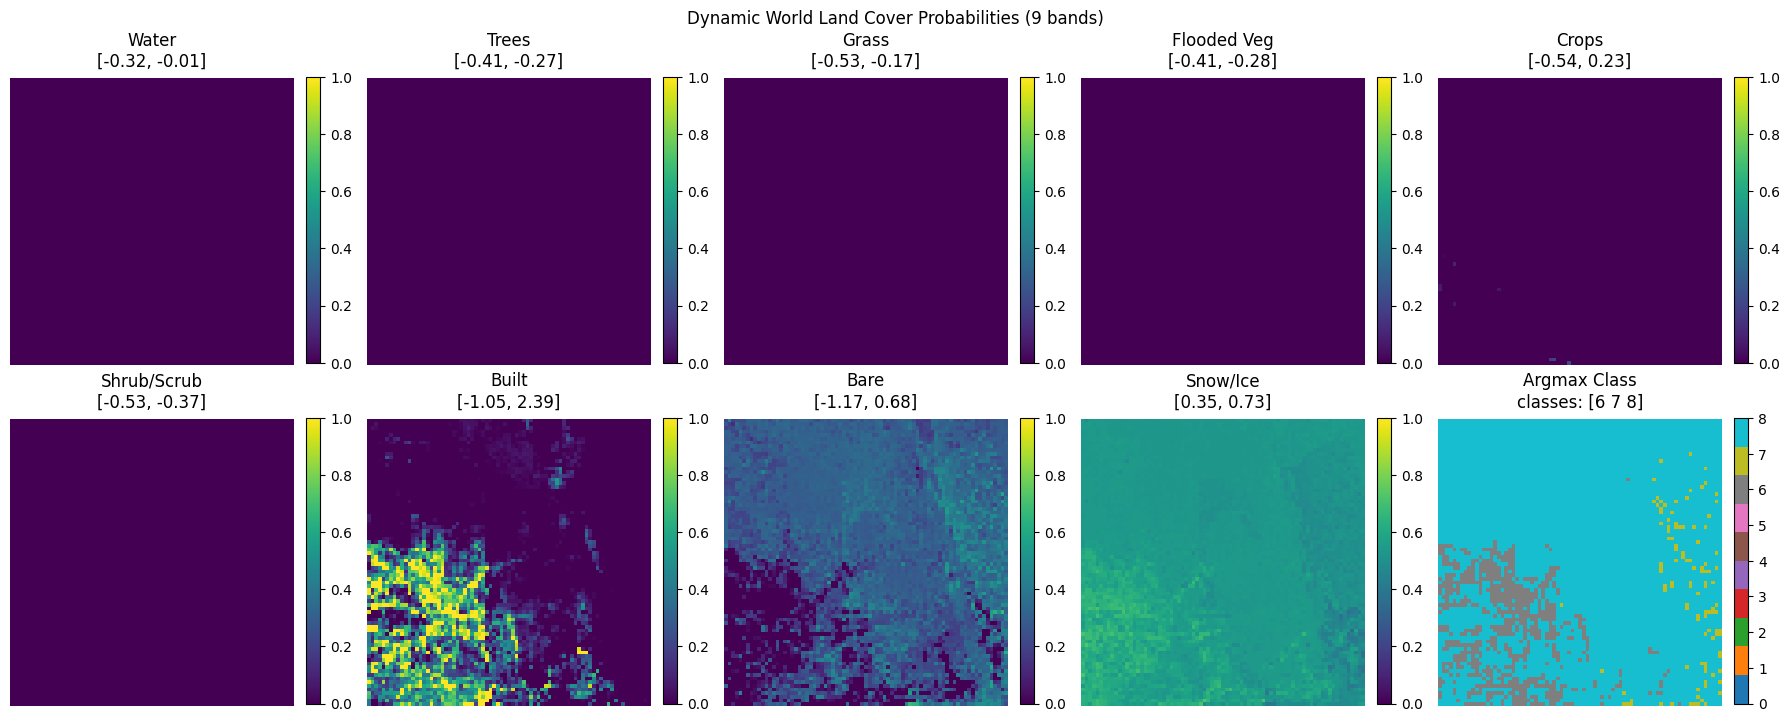

In [ ]:
# Dynamic World (channels 63-71) - 9 probability bands
dw_names = [
    'Water',
    'Trees', 
    'Grass',
    'Flooded Veg',
    'Crops',
    'Shrub/Scrub',
    'Built',
    'Bare',
    'Snow/Ice',
]

fig, axes = plt.subplots(2, 5, figsize=(18, 7))
axes = axes.flatten()

dw_start = channel_indices['dynamic_world'][0]

for i, name in enumerate(dw_names):
    ax = axes[i]
    ch = dw_start + i
    data = x[ch].numpy()
    valid_mask_i = mask[ch].numpy()
    valid = data[valid_mask_i]
    display_data = np.where(valid_mask_i, data, np.nan)
    
    if len(valid) > 0:
        # Probabilities are 0-1
        im = ax.imshow(display_data, vmin=0, vmax=1, cmap='viridis')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{name}\n[{valid.min():.2f}, {valid.max():.2f}]')
    else:
        ax.imshow(display_data, cmap='viridis')
        ax.set_title(f'{name}\n(no valid data)')
    ax.axis('off')

# Show argmax classification in last panel
ax = axes[9]
dw_probs = x[dw_start:dw_start+9].numpy()
dw_valid = mask[dw_start].numpy()  # Use first band's mask
dw_class = np.argmax(dw_probs, axis=0)
dw_class_display = np.where(dw_valid, dw_class, np.nan)
im = ax.imshow(dw_class_display, vmin=0, vmax=8, cmap='tab10')
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_title(f'Argmax Class\nclasses: {np.unique(dw_class[dw_valid]).astype(int)}')
ax.axis('off')

plt.tight_layout()
plt.suptitle('Dynamic World Land Cover Probabilities (9 bands)', y=1.02)
plt.show()

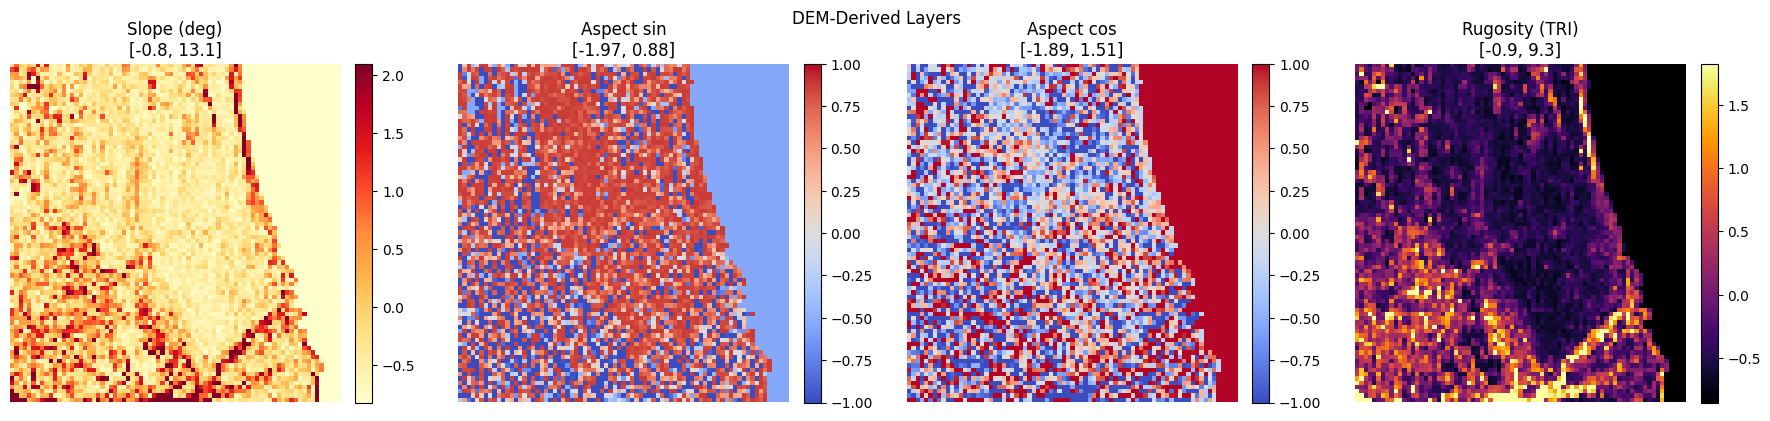

In [ ]:
# DEM-Derived Layers: Slope, Aspect (sin/cos), Rugosity (TRI)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# Slope
ax = axes[0]
slope_ch = channel_indices['slope'][0]
data = x[slope_ch].numpy()
valid_mask_i = mask[slope_ch].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    vmin, vmax = np.percentile(valid, [2, 98])
    im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='YlOrRd')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Slope (deg)\n[{valid.min():.1f}, {valid.max():.1f}]')
else:
    ax.imshow(display_data)
    ax.set_title('Slope\n(no valid data)')
ax.axis('off')

# Aspect sin
ax = axes[1]
asp_start = channel_indices['aspect'][0]
data = x[asp_start].numpy()
valid_mask_i = mask[asp_start].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    im = ax.imshow(display_data, vmin=-1, vmax=1, cmap='coolwarm')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Aspect sin\n[{valid.min():.2f}, {valid.max():.2f}]')
ax.axis('off')

# Aspect cos
ax = axes[2]
data = x[asp_start + 1].numpy()
valid_mask_i = mask[asp_start + 1].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    im = ax.imshow(display_data, vmin=-1, vmax=1, cmap='coolwarm')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Aspect cos\n[{valid.min():.2f}, {valid.max():.2f}]')
ax.axis('off')

# Rugosity (TRI)
ax = axes[3]
rug_ch = channel_indices['rugosity'][0]
data = x[rug_ch].numpy()
valid_mask_i = mask[rug_ch].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    vmin, vmax = np.percentile(valid, [2, 98])
    im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='inferno')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Rugosity (TRI)\n[{valid.min():.1f}, {valid.max():.1f}]')
else:
    ax.imshow(display_data)
    ax.set_title('Rugosity\n(no valid data)')
ax.axis('off')

plt.tight_layout()
plt.suptitle('DEM-Derived Layers', y=1.02)
plt.show()

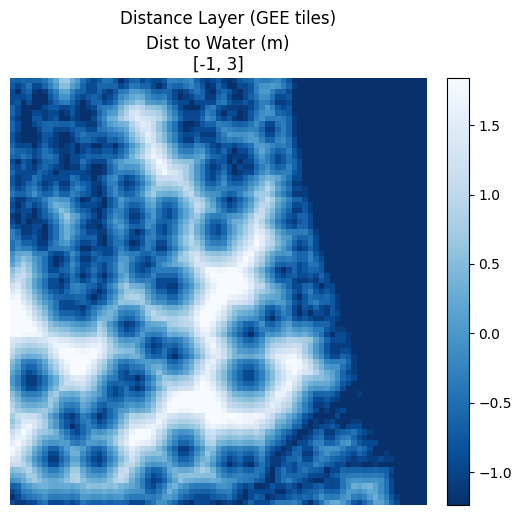

In [ ]:
# Distance Layer: Water
fig, ax = plt.subplots(1, 1, figsize=(6, 5))

ch = channel_indices['dist_water'][0]
data = x[ch].numpy()
valid_mask_i = mask[ch].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)

if len(valid) > 0:
    vmin, vmax = np.percentile(valid, [2, 98])
    im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='Blues_r')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Dist to Water (m)\n[{valid.min():.0f}, {valid.max():.0f}]')
else:
    ax.imshow(display_data, cmap='Blues_r')
    ax.set_title('Dist to Water\n(no valid data / not downloaded)')
ax.axis('off')

plt.tight_layout()
plt.suptitle('Distance Layer (GEE tiles)', y=1.02)
plt.show()

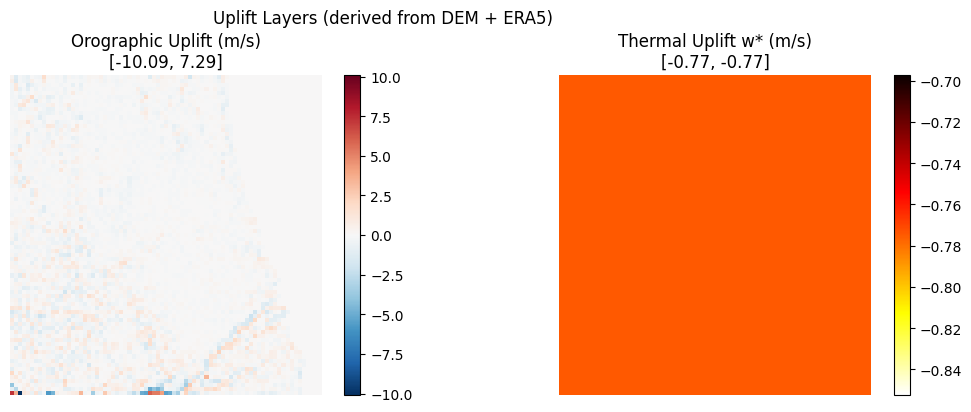

In [ ]:
# Uplift Layers: Orographic and Thermal
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Orographic uplift
ax = axes[0]
oro_ch = channel_indices['orographic_uplift'][0]
data = x[oro_ch].numpy()
valid_mask_i = mask[oro_ch].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    vmax = max(abs(valid.min()), abs(valid.max()))
    im = ax.imshow(display_data, vmin=-vmax, vmax=vmax, cmap='RdBu_r')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Orographic Uplift (m/s)\n[{valid.min():.2f}, {valid.max():.2f}]')
else:
    ax.imshow(display_data)
    ax.set_title('Orographic Uplift\n(no valid data)')
ax.axis('off')

# Thermal uplift
ax = axes[1]
therm_ch = channel_indices['thermal_uplift'][0]
data = x[therm_ch].numpy()
valid_mask_i = mask[therm_ch].numpy()
valid = data[valid_mask_i]
display_data = np.where(valid_mask_i, data, np.nan)
if len(valid) > 0:
    vmin, vmax = np.percentile(valid, [2, 98])
    im = ax.imshow(display_data, vmin=vmin, vmax=vmax, cmap='hot_r')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_title(f'Thermal Uplift w* (m/s)\n[{valid.min():.2f}, {valid.max():.2f}]')
else:
    ax.imshow(display_data)
    ax.set_title('Thermal Uplift\n(no valid data)')
ax.axis('off')

plt.tight_layout()
plt.suptitle('Uplift Layers (derived from DEM + ERA5)', y=1.02)
plt.show()